<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/mathematical_biology/mathbio_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Mathematical Biology* — `mathbio_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# MathBio Ch 3 Figures — Colab Notebook
**Mathematical Biology · Chapter 3: Spatial Variations**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch03/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Diffusion: Gaussian, $\sigma\sim\sqrt{t}$, eigenmodes | §3.1 |
| fig02 | KPP-Fisher wave: profiles, propagation, phase plane | §3.2 |
| fig03 | Turing: dispersion, 1D Schnakenberg, 2D Gray-Scott | §3.3 |
| fig04 | Turing: conditions, threshold $D_v/D_u$, wavelength | §3.3 |
| fig05 | Chemotaxis: random walk, aggregation, blow-up | §3.4 |

---
## fig01 · Diffusion Equation (§3.1)

**Left**: Gaussian spreading — width grows with $t$. **Centre**: $\sigma=\sqrt{2Dt}\sim\sqrt{t}$ for three $D$. **Right**: Eigenmodes on $[0,L]$ — higher modes decay faster.

  saved -> figures/ch03/fig01_diffusion.png


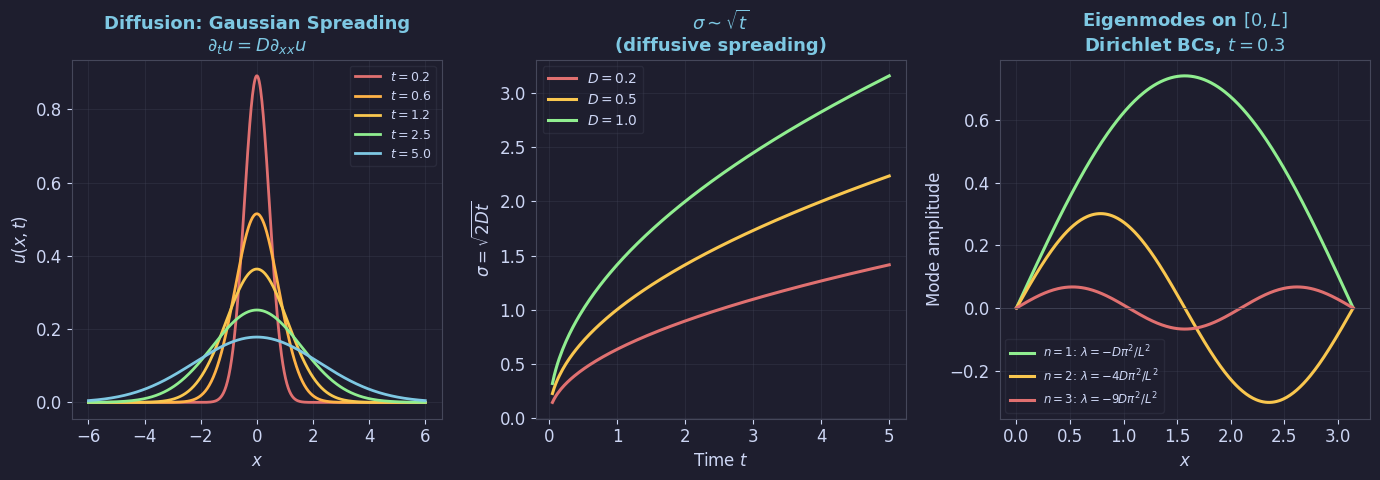

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: Diffusion — Gaussian spreading + eigenmode decay (§3.1) ─────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
x=np.linspace(-6,6,500); D=0.5
ax=axes[0]
for t_val,col,lab in [(0.2,RED,'$t=0.2$'),(0.6,ORANGE,'$t=0.6$'),
                       (1.2,YELLOW,'$t=1.2$'),(2.5,GREEN,'$t=2.5$'),(5.0,BLUE,'$t=5.0$')]:
    sig2=2*D*t_val
    ax.plot(x,np.exp(-x**2/(2*sig2))/np.sqrt(2*np.pi*sig2),color=col,lw=2.0,label=lab)
ax.set_xlabel('$x$'); ax.set_ylabel('$u(x,t)$')
ax.set_title(r'Diffusion: Gaussian Spreading'+'\n'+r'$\partial_t u=D\partial_{xx}u$',color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True)

t_arr=np.linspace(0.05,5,200)
ax2=axes[1]
for D_val,col,lab in [(0.2,RED,'$D=0.2$'),(0.5,YELLOW,'$D=0.5$'),(1.0,GREEN,'$D=1.0$')]:
    ax2.plot(t_arr,np.sqrt(2*D_val*t_arr),color=col,lw=2.2,label=lab)
ax2.set_xlabel('Time $t$'); ax2.set_ylabel(r'$\sigma=\sqrt{2Dt}$')
ax2.set_title(r'$\sigma\sim\sqrt{t}$'+'\n(diffusive spreading)',color=BLUE)
ax2.legend(fontsize=10,labelcolor=FG); ax2.grid(True)

L=np.pi; x3=np.linspace(0,L,300); D3=1.0
ax3=axes[2]
for n,col,lab in [(1,GREEN,r'$n=1$: $\lambda=-D\pi^2/L^2$'),
                   (2,YELLOW,r'$n=2$: $\lambda=-4D\pi^2/L^2$'),
                   (3,RED,r'$n=3$: $\lambda=-9D\pi^2/L^2$')]:
    lam=-D3*(n*np.pi/L)**2
    ax3.plot(x3,np.sin(n*np.pi*x3/L)*np.exp(lam*0.3),color=col,lw=2.2,label=lab)
ax3.axhline(0,color=EDGE,lw=0.5)
ax3.set_xlabel('$x$'); ax3.set_ylabel('Mode amplitude')
ax3.set_title('Eigenmodes on $[0,L]$\nDirichlet BCs, $t=0.3$',color=BLUE)
ax3.legend(fontsize=8.5,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig01_diffusion.png',fig)


---
## fig02 · KPP-Fisher Travelling Wave (§3.2)

**Left**: Wave profiles — steeper for larger $c$. **Centre**: Space-time propagation at $c_{\min}$. **Right**: Phase plane — heteroclinic orbit $(1,0)\to(0,0)$.

  saved -> figures/ch03/fig02_kpp_fisher.png


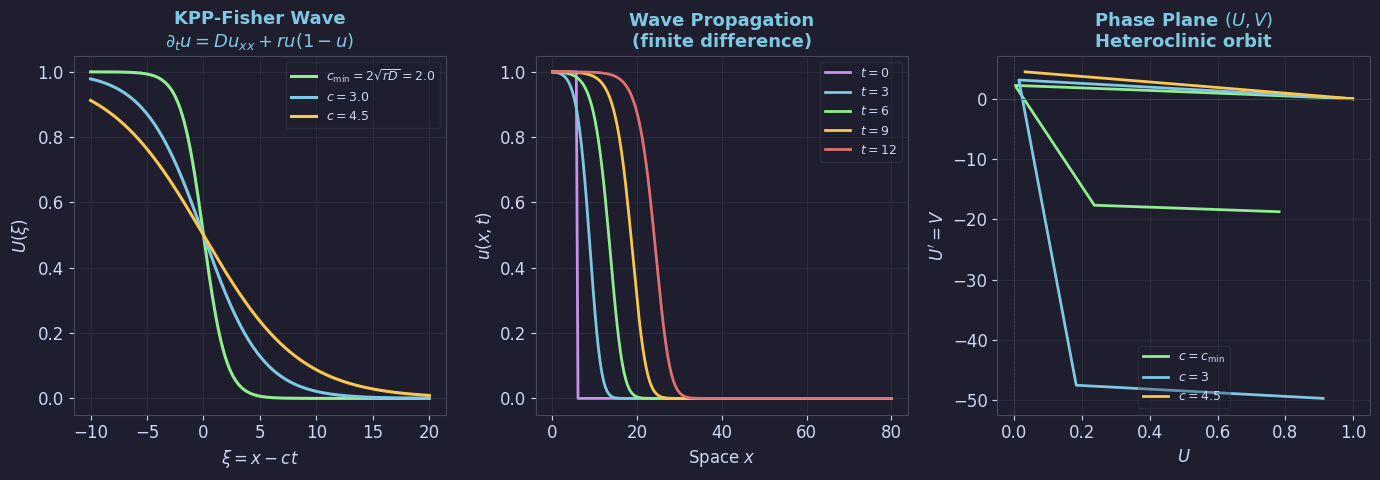

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: KPP-Fisher travelling wave (§3.2) ─────────────────────────────
D_k,r_k=1.0,1.0; c_min=2*np.sqrt(r_k*D_k)
xi=np.linspace(-10,20,500)
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)

ax=axes[0]
for c_val,col,lab in [(c_min,GREEN,f'$c_{{\\min}}=2\\sqrt{{rD}}={c_min:.1f}$'),
                       (3.0,BLUE,'$c=3.0$'),(4.5,YELLOW,'$c=4.5$')]:
    lam=(c_val-np.sqrt(max(c_val**2-4*r_k*D_k,0)))/(2*D_k)
    ax.plot(xi,1/(1+np.exp(lam*xi)),color=col,lw=2.2,label=lab)
ax.set_xlabel(r'$\xi=x-ct$'); ax.set_ylabel(r'$U(\xi)$')
ax.set_title('KPP-Fisher Wave\n'+r'$\partial_t u=Du_{xx}+ru(1-u)$',color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True)

ax2=axes[1]
Nx=200; dx=0.4; dt=0.01
x2=np.linspace(0,Nx*dx,Nx); u=np.zeros(Nx); u[:15]=1.0
u_snap={0:u.copy()}; t_now=0
targets={3,6,9,12}
while t_now<12+dt:
    lap=np.roll(u,-1)-2*u+np.roll(u,1); lap[0]=lap[-1]=0
    u=u+dt*(D_k*lap/dx**2+r_k*u*(1-u)); u=np.clip(u,0,1); t_now+=dt
    for tgt in targets:
        if tgt not in u_snap and abs(t_now-tgt)<dt*0.6:
            u_snap[tgt]=u.copy()
for t_t,col in [(0,PURPLE),(3,BLUE),(6,GREEN),(9,YELLOW),(12,RED)]:
    ax2.plot(x2,u_snap[t_t],color=col,lw=2.0,label=f'$t={t_t}$')
ax2.set_xlabel('Space $x$'); ax2.set_ylabel('$u(x,t)$')
ax2.set_title('Wave Propagation\n(finite difference)',color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)

ax3=axes[2]
def wave_ode(xi,y,c,D=1.0,r=1.0):
    U,V=y; return [V,-(c/D)*V-(r/D)*U*(1-U)]
for c_val,col,lab in [(c_min,GREEN,f'$c=c_{{\\min}}$'),(3.0,BLUE,'$c=3$'),(4.5,YELLOW,'$c=4.5$')]:
    sol=solve_ivp(wave_ode,[0,-30],[0.999,0],args=(c_val,),max_step=0.05,dense_output=True)
    tr=sol.sol(np.linspace(0,-30,2000))
    mask=(tr[0]>=0)&(tr[0]<=1)
    ax3.plot(tr[0][mask],tr[1][mask],color=col,lw=2.0,label=lab)
ax3.axhline(0,color=EDGE,lw=0.5); ax3.axvline(0,color=EDGE,lw=0.5,ls='--')
ax3.set_xlabel('$U$'); ax3.set_ylabel("$U'=V$")
ax3.set_title('Phase Plane $(U,V)$\nHeteroclinic orbit',color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True); ax3.set_xlim(-0.05,1.05)
plt.tight_layout(pad=1.2)
save('fig02_kpp_fisher.png',fig)


---
## fig03 · Turing Instability + Patterns (§3.3)

**Left**: Dispersion relation $\sigma_+(k^2)$ — Turing unstable band. **Centre**: 1D Schnakenberg pattern. **Right**: 2D Gray-Scott spots.

  saved -> figures/ch03/fig03_turing.png


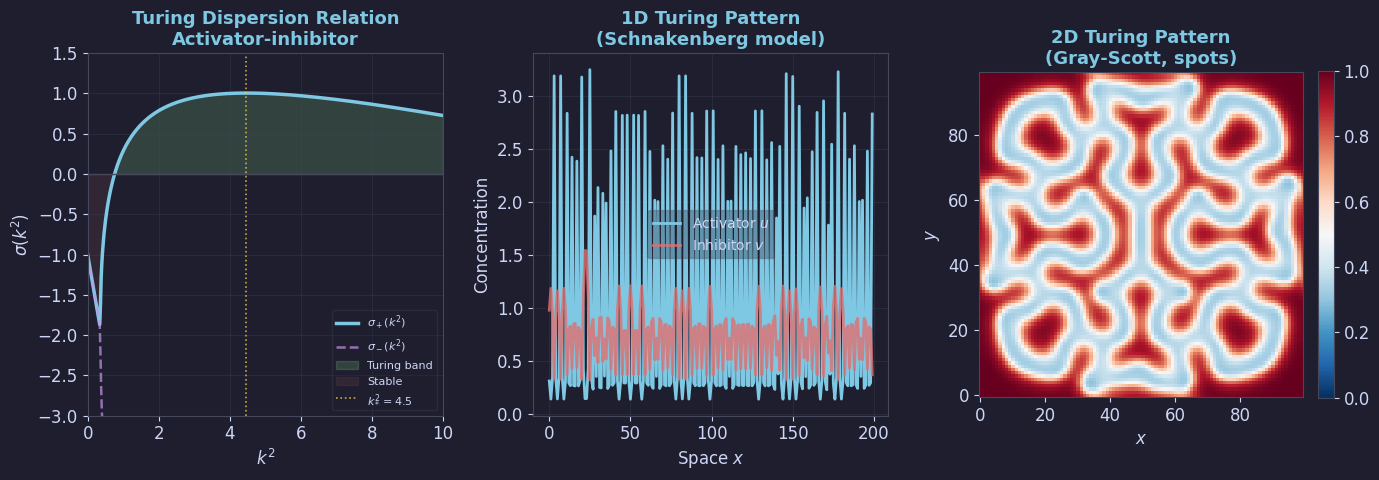

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Turing dispersion + 1D pattern + 2D spots (§3.3) ──────────────
Du,Dv=0.1,5.0; fu,fv,gu,gv=2.0,-5.0,3.0,-4.0
k2=np.linspace(0,10,500)
h_k=(fu+gv)-(Du+Dv)*k2; det_k=(fu-Du*k2)*(gv-Dv*k2)-fv*gu; disc=h_k**2-4*det_k
sigma_p=np.where(disc>=0,(h_k+np.sqrt(np.maximum(disc,0)))/2,h_k/2)
sigma_m=np.where(disc>=0,(h_k-np.sqrt(np.maximum(disc,0)))/2,h_k/2)
k_star2=k2[sigma_p.argmax()]

fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)
ax=axes[0]
ax.plot(k2,sigma_p,color=BLUE,lw=2.5,label=r'$\sigma_+(k^2)$')
ax.plot(k2,sigma_m,color=PURPLE,lw=1.8,ls='--',label=r'$\sigma_-(k^2)$',alpha=0.7)
ax.axhline(0,color=EDGE,lw=1.0)
ax.fill_between(k2,sigma_p,0,where=(sigma_p>0),color=GREEN,alpha=0.18,label='Turing band')
ax.fill_between(k2,sigma_p,0,where=(sigma_p<0),color=RED,alpha=0.10,label='Stable')
ax.axvline(k_star2,color=YELLOW,lw=1.2,ls=':',alpha=0.8,label=f'$k^2_*={k_star2:.1f}$')
ax.set_xlabel('$k^2$'); ax.set_ylabel(r'$\sigma(k^2)$')
ax.set_title('Turing Dispersion Relation\nActivator-inhibitor',color=BLUE)
ax.legend(fontsize=8,labelcolor=FG,loc='lower right'); ax.grid(True)
ax.set_xlim(0,10); ax.set_ylim(-3,1.5)

def run_schnakenberg(Nx=200,steps=80000,dt=0.05,Du=0.05,Dv=2.0,a=0.1,b=0.9):
    np.random.seed(42)
    ss_u=a+b; ss_v=b/(a+b)**2
    u=ss_u+0.02*(np.random.rand(Nx)-0.5); v=ss_v+0.02*(np.random.rand(Nx)-0.5)
    ku=Du*dt; kv=Dv*dt
    for _ in range(steps):
        lap_u=np.roll(u,-1)-2*u+np.roll(u,1)
        lap_v=np.roll(v,-1)-2*v+np.roll(v,1)
        u=u+dt*(a-u+u**2*v)+ku*lap_u; v=v+dt*(b-u**2*v)+kv*lap_v
        u=np.clip(u,1e-6,10); v=np.clip(v,1e-6,10)
    return u,v
u1d,v1d=run_schnakenberg()
ax2=axes[1]
ax2.plot(np.arange(len(u1d)),u1d,color=BLUE,lw=2.0,label='Activator $u$')
ax2.plot(np.arange(len(u1d)),v1d,color=RED,lw=2.0,label='Inhibitor $v$',alpha=0.8)
ax2.set_xlabel('Space $x$'); ax2.set_ylabel('Concentration')
ax2.set_title('1D Turing Pattern\n(Schnakenberg model)',color=BLUE)
ax2.legend(fontsize=10,labelcolor=FG); ax2.grid(True)

def run_gray_scott(N=100,steps=5000,Du=0.16,Dv=0.08,F=0.060,k=0.062):
    np.random.seed(5)
    u=np.ones((N,N)); v=np.zeros((N,N))
    s=10; mid=N//2
    u[mid-s:mid+s,mid-s:mid+s]=0.50; v[mid-s:mid+s,mid-s:mid+s]=0.25
    u+=0.01*np.random.randn(N,N); v+=0.01*np.random.randn(N,N)
    u=np.clip(u,0,1); v=np.clip(v,0,1)
    for _ in range(steps):
        Lu=(np.roll(u,-1,0)+np.roll(u,1,0)+np.roll(u,-1,1)+np.roll(u,1,1)-4*u)
        Lv=(np.roll(v,-1,0)+np.roll(v,1,0)+np.roll(v,-1,1)+np.roll(v,1,1)-4*v)
        uvv=u*v*v; u+=Du*Lu-uvv+F*(1-u); v+=Dv*Lv+uvv-(F+k)*v
        u=np.clip(u,0,1); v=np.clip(v,0,1)
    return u
u2d=run_gray_scott()
ax3=axes[2]
im=ax3.imshow(u2d,cmap='RdBu_r',origin='lower',vmin=0,vmax=1)
plt.colorbar(im,ax=ax3,fraction=0.046,pad=0.04)
ax3.set_title('2D Turing Pattern\n(Gray-Scott, spots)',color=BLUE)
ax3.set_xlabel('$x$'); ax3.set_ylabel('$y$')
plt.tight_layout(pad=1.2)
save('fig03_turing.png',fig)


---
## fig04 · Turing Conditions + Threshold (§3.3)

**Left**: Necessary conditions summary. **Centre**: $\sigma_{\max}$ vs $D_v/D_u$ — instability threshold. **Right**: Pattern wavelength $\Lambda\sim\sqrt{D_u}$.

  saved -> figures/ch03/fig04_turing_conditions.png


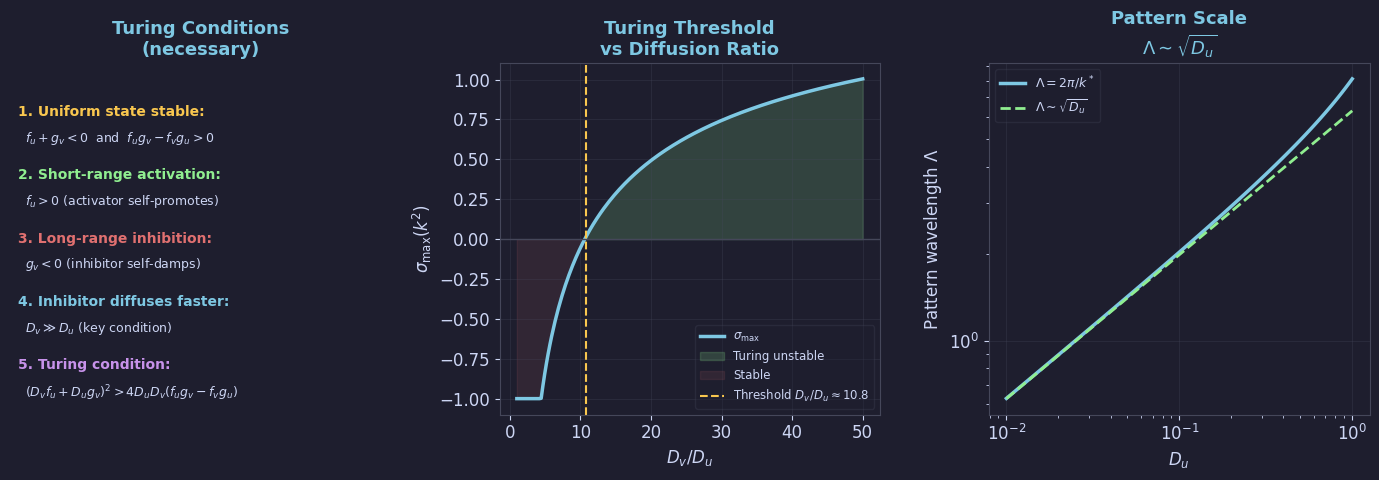

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: Turing conditions + threshold + wavelength (§3.3) ─────────────
fu2,fv2,gu2,gv2=2.0,-5.0,3.0,-4.0; Du2=0.1
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)

ax=axes[0]; ax.axis('off'); ax.set_title('Turing Conditions\n(necessary)',color=BLUE)
conditions=[
    ('1. Uniform state stable:',r'$f_u+g_v<0$  and  $f_ug_v-f_vg_u>0$',YELLOW),
    ('2. Short-range activation:',r'$f_u>0$ (activator self-promotes)',GREEN),
    ('3. Long-range inhibition:',r'$g_v<0$ (inhibitor self-damps)',RED),
    ('4. Inhibitor diffuses faster:',r'$D_v\gg D_u$ (key condition)',BLUE),
    ('5. Turing condition:',r'$(D_vf_u+D_ug_v)^2>4D_uD_v(f_ug_v-f_vg_u)$',PURPLE),
]
for i,(title,cond,col) in enumerate(conditions):
    y=0.88-i*0.18
    ax.text(0.02,y,title,transform=ax.transAxes,fontsize=10,color=col,fontweight='bold',va='top')
    ax.text(0.04,y-0.07,cond,transform=ax.transAxes,fontsize=9,color=FG,va='top')

d_ratio=np.linspace(1,50,200); sigma_max_arr=np.zeros_like(d_ratio)
turing_ok=np.zeros_like(d_ratio,dtype=bool)
for i,dr in enumerate(d_ratio):
    Dv2=Du2*dr; k2v=np.linspace(0,50,600)
    hk=(fu2+gv2)-(Du2+Dv2)*k2v; dk=(fu2-Du2*k2v)*(gv2-Dv2*k2v)-fv2*gu2
    disc2=hk**2-4*dk; sp=np.where(disc2>=0,(hk+np.sqrt(np.maximum(disc2,0)))/2,hk/2)
    sigma_max_arr[i]=sp.max(); turing_ok[i]=sp.max()>0
ax2=axes[1]
ax2.plot(d_ratio,sigma_max_arr,color=BLUE,lw=2.5,label=r'$\sigma_{\max}$')
ax2.axhline(0,color=EDGE,lw=1.0)
ax2.fill_between(d_ratio,sigma_max_arr,0,where=(sigma_max_arr>0),color=GREEN,alpha=0.18,label='Turing unstable')
ax2.fill_between(d_ratio,sigma_max_arr,0,where=(sigma_max_arr<0),color=RED,alpha=0.10,label='Stable')
thresh_idx=np.where(turing_ok)[0][0] if turing_ok.any() else 0
ax2.axvline(d_ratio[thresh_idx],color=YELLOW,lw=1.5,ls='--',
            label=f'Threshold $D_v/D_u\\approx{d_ratio[thresh_idx]:.1f}$')
ax2.set_xlabel('$D_v/D_u$'); ax2.set_ylabel(r'$\sigma_{\max}(k^2)$')
ax2.set_title('Turing Threshold\nvs Diffusion Ratio',color=BLUE)
ax2.legend(fontsize=8.5,labelcolor=FG); ax2.grid(True)

Du3=np.logspace(-2,0,100); Dv3=5.0
k_star_arr=np.sqrt((Dv3*fu2+Du3*gv2)/(2*Du3*Dv3))
wavelength=2*np.pi/k_star_arr
ax3=axes[2]
ax3.loglog(Du3,wavelength,color=BLUE,lw=2.5,label=r'$\Lambda=2\pi/k^*$')
ax3.loglog(Du3,2*np.pi/np.sqrt(fu2/(2*Du3)),color=GREEN,lw=2.0,ls='--',
           label=r'$\Lambda\sim\sqrt{D_u}$')
ax3.set_xlabel('$D_u$'); ax3.set_ylabel('Pattern wavelength $\\Lambda$')
ax3.set_title('Pattern Scale\n'+r'$\Lambda\sim\sqrt{D_u}$',color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig04_turing_conditions.png',fig)


---
## fig05 · Chemotaxis: Keller-Segel (§3.4)

**Left**: Random walk vs biased chemotactic drift. **Centre**: 1D cell aggregation toward chemoattractant. **Right**: Blow-up diagram $M$ vs $T_{\rm blowup}$; $M>M_c=8\pi D/\chi$ leads to collapse.

  saved -> figures/ch03/fig05_chemotaxis.png


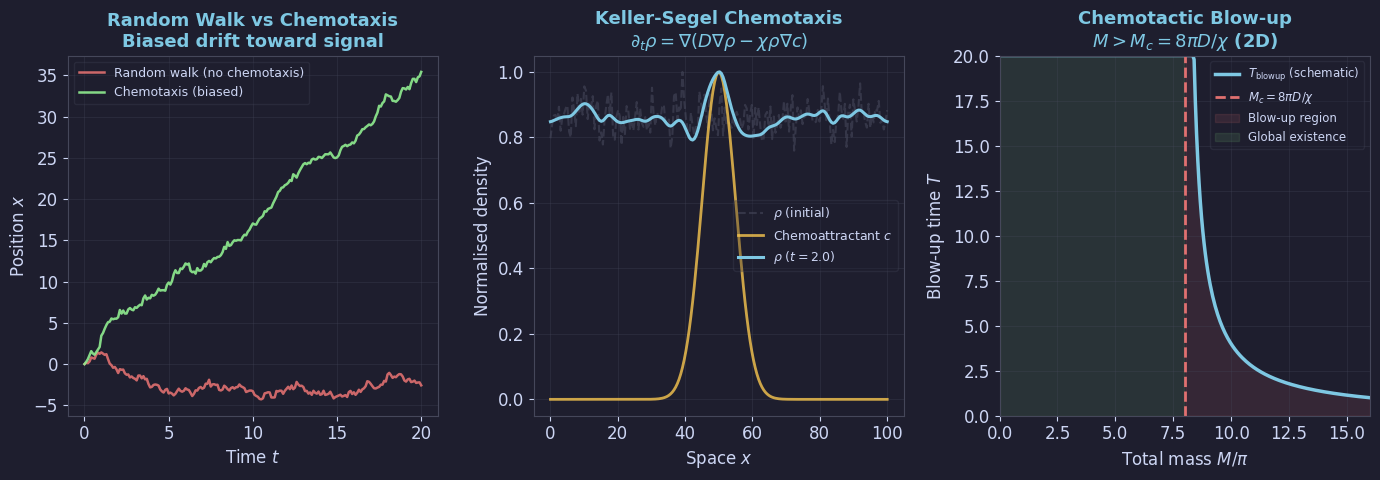

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: Chemotaxis — Keller-Segel (§3.4) ──────────────────────────────
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)

np.random.seed(42)
n_steps=200; dt_rw=0.1; D_rw=0.5; v_drift=1.5
t_rw=np.linspace(0,n_steps*dt_rw,n_steps+1)
ax=axes[0]
for col,lab,drift in [(RED,'Random walk (no chemotaxis)',0),(GREEN,'Chemotaxis (biased)',1)]:
    x_rw=np.zeros(n_steps+1)
    for j in range(n_steps):
        x_rw[j+1]=x_rw[j]+drift*v_drift*dt_rw+np.sqrt(2*D_rw*dt_rw)*np.random.randn()
    ax.plot(t_rw,x_rw,color=col,lw=1.8,label=lab,alpha=0.9)
ax.set_xlabel('Time $t$'); ax.set_ylabel('Position $x$')
ax.set_title('Random Walk vs Chemotaxis\nBiased drift toward signal',color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True)

ax2=axes[1]
Nx2=200; dx2=0.5; dt2=0.001; T2=2.0
x2=np.linspace(0,Nx2*dx2,Nx2)
c_ks=np.exp(-(x2-50)**2/50)
rho=np.ones(Nx2)+0.05*np.random.randn(Nx2); rho=np.clip(rho,0,None)
D_ks=0.5; chi=2.0
ax2.plot(x2,rho/rho.max(),color=EDGE,lw=1.5,ls='--',alpha=0.6,label='$\\rho$ (initial)')
ax2.plot(x2,c_ks,color=YELLOW,lw=2.0,label='Chemoattractant $c$',alpha=0.8)
for _ in range(int(T2/dt2)):
    lap_rho=np.roll(rho,-1)-2*rho+np.roll(rho,1)
    dc_dx=(np.roll(c_ks,-1)-np.roll(c_ks,1))/(2*dx2)
    flux=chi*rho*dc_dx; dflux=(np.roll(flux,-1)-np.roll(flux,1))/(2*dx2)
    rho=rho+dt2*(D_ks*lap_rho/dx2**2-dflux); rho=np.clip(rho,0,None)
ax2.plot(x2,rho/rho.max(),color=BLUE,lw=2.2,label=f'$\\rho$ ($t={T2}$)')
ax2.set_xlabel('Space $x$'); ax2.set_ylabel('Normalised density')
ax2.set_title('Keller-Segel Chemotaxis\n'+r'$\partial_t\rho=\nabla(D\nabla\rho-\chi\rho\nabla c)$',
              color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)

M_arr=np.linspace(0,16*np.pi,300); M_c=8*np.pi
T_blowup=np.where(M_arr>M_c,M_c/(M_arr-M_c+0.01),20); T_blowup=np.minimum(T_blowup,20)
ax3=axes[2]
ax3.plot(M_arr/np.pi,T_blowup,color=BLUE,lw=2.5,label=r'$T_{\rm blowup}$ (schematic)')
ax3.axvline(M_c/np.pi,color=RED,lw=2.0,ls='--',label='$M_c=8\\pi D/\\chi$')
ax3.fill_between(M_arr/np.pi,0,np.minimum(T_blowup,20),
                 where=(M_arr>M_c),color=RED,alpha=0.12,label='Blow-up region')
ax3.fill_between(M_arr/np.pi,0,20,where=(M_arr<=M_c),color=GREEN,alpha=0.10,label='Global existence')
ax3.set_xlabel('Total mass $M/\\pi$'); ax3.set_ylabel('Blow-up time $T$')
ax3.set_title('Chemotactic Blow-up\n$M>M_c=8\\pi D/\\chi$ (2D)',color=BLUE)
ax3.legend(fontsize=8.5,labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0,M_arr.max()/np.pi); ax3.set_ylim(0,20)
plt.tight_layout(pad=1.2)
save('fig05_chemotaxis.png',fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch03'
saved=sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved: print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name='mathbio_ch03_figures.zip'
with zipfile.ZipFile(zip_name,'w',zipfile.ZIP_DEFLATED) as zf:
    for fname in saved: zf.write(f'{OUTDIR}/{fname}',arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_diffusion.png  (231 KB)
  fig02_kpp_fisher.png  (194 KB)
  fig03_turing.png  (296 KB)
  fig04_turing_conditions.png  (181 KB)
  fig05_chemotaxis.png  (243 KB)
Zip: mathbio_ch03_figures.zip  (1098 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>